# NoteScope: AI-written vs human-written Community Notes

**Business question:** do AI-written Community Notes on X reach "Helpful" status more often and faster than human-written ones, and how much attention (ratings) do they get?

This notebook reproduces the numbers in the README from the local DuckDB database. It uses the SQL files in `../sql/`, so every table below can also be produced with `python scripts/run_sql.py sql/<file>.sql`.

How to read it: *AI* = notes from accounts enrolled as `apiEarnedIn` (the account's **current** state). *Other* = all other authors. Comparisons use the window from the first AI note (Sep 2025) onward. Results are descriptive, not causal.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# Find the repository root whether the notebook is run from the repo or from notebooks/
REPO = Path.cwd()
if not (REPO / "sql").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
from notescope.config import DB_PATH

con = duckdb.connect(str(DB_PATH), read_only=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
COLORS = {"AI": "#2F5BD3", "Other": "#8A93A3"}


def run_sql_file(name):
    """Run every statement of sql/<name> and return the results as a list of DataFrames."""
    text = (REPO / "sql" / name).read_text(encoding="utf-8")
    frames = []
    for statement in text.split(";"):
        has_code = any(l.strip() and not l.strip().startswith("--") for l in statement.splitlines())
        if has_code:
            frames.append(con.sql(statement).df())
    return frames


print("Database:", DB_PATH)

Database: /Users/yigitertenvarlik/Desktop/NoteScope/data/processed/notescope.duckdb


## 1. Data quality
Row counts and the join checks. Negative durations and ratings before note creation should be 0.

In [2]:
for df in run_sql_file("04_data_quality.sql"):
    display(df)
for df in run_sql_file("07_ratings_quality.sql"):
    display(df)

,metric,value
0,note_status rows,3402288
1,enrollment rows,1504712
2,notes rows (note files present),3194212
3,AI writer accounts (apiEarnedIn),39
4,note_status rows without a notes row (deleted ...,456168
5,note_status authors missing from enrollment,173191
6,negative hours to first status,0


,metric,value
0,notes with ratings,3360685
1,ratings in total,241643451
2,rated notes missing in note_status,90622
3,notes where ratings far exceed approx raters (...,100083
4,ratings before note creation,0


## 2. How often do notes become Helpful?
Share of notes currently rated Helpful, by author group, over all time and since the first AI note.

In [3]:
display(run_sql_file("01_overview.sql")[0])

,author_group,current_status,notes,pct_of_group
0,AI,CURRENTLY_RATED_HELPFUL,35581,10.74
1,AI,CURRENTLY_RATED_NOT_HELPFUL,3303,1.00
2,AI,NEEDS_MORE_RATINGS,292479,88.27
3,Other,CURRENTLY_RATED_HELPFUL,252025,8.21
4,Other,CURRENTLY_RATED_NOT_HELPFUL,134283,4.37
5,Other,NEEDS_MORE_RATINGS,2684617,87.42


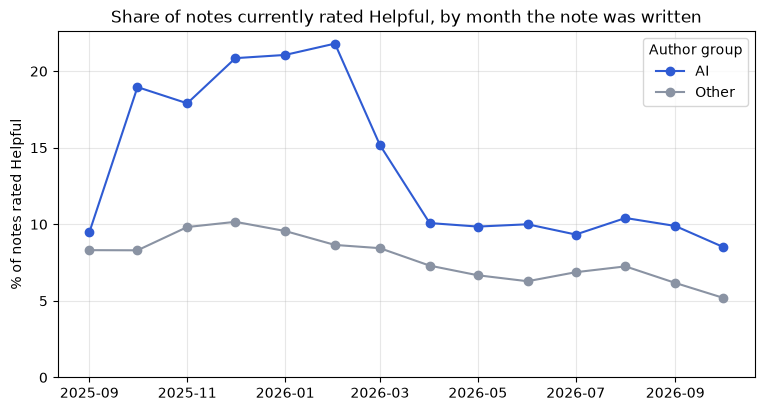

author_group,AI,Other
month,,
2025-09-01,9.47,8.31
2025-10-01,18.96,8.30
2025-11-01,17.90,9.82
2025-12-01,20.85,10.16
2026-01-01,21.06,9.56
2026-02-01,21.80,8.65
2026-03-01,15.18,8.44
2026-04-01,10.08,7.30
2026-05-01,9.85,6.67


In [4]:
monthly = run_sql_file("02_helpful_rate_by_month.sql")[0]
fig, ax = plt.subplots(figsize=(9, 4.5))
for group, df in monthly.groupby("author_group"):
    ax.plot(df["month"], df["pct_helpful_now"], marker="o", label=group, color=COLORS[group])
ax.set_title("Share of notes currently rated Helpful, by month the note was written")
ax.set_ylabel("% of notes rated Helpful")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(title="Author group")
plt.show()
monthly.pivot(index="month", columns="author_group", values="pct_helpful_now")

**Reading:** AI notes have a higher Helpful share in every month, but the gap shrinks after AI note volume jumps in spring 2026. The latest month is still maturing for both groups.

## 3. How fast do notes reach a first status?
Hours from creation to the first status other than "Needs More Ratings" (only notes that left that state).

In [5]:
display(run_sql_file("03_time_to_first_status.sql")[0])

,author_group,first_non_nmr_status,notes,median_hours,p90_hours
0,AI,CURRENTLY_RATED_HELPFUL,40770,8.5,55.0
1,AI,CURRENTLY_RATED_NOT_HELPFUL,5150,2.4,33.5
2,Other,CURRENTLY_RATED_HELPFUL,81214,8.1,51.0
3,Other,CURRENTLY_RATED_NOT_HELPFUL,57793,3.3,23.3


## 4. How many ratings do notes get?
Ratings are summarised to one row per note (`note_ratings`). Notes of the same month have had the same time to collect ratings, so the monthly comparison avoids an age bias.

In [6]:
frames = run_sql_file("05_ratings_per_note.sql")
display(frames[0])
display(frames[1])

,author_group,notes,pct_with_any_rating,median_ratings,median_raters,p90_ratings,pct_5_plus,pct_10_plus,pct_repeat_suspect
0,AI,331363,100.0,10.0,10.0,62.0,72.7,50.4,1.1
1,Other,838049,99.9,21.0,21.0,182.0,78.9,66.0,3.1


,author_group,current_status,notes,median_ratings,pct_5_plus
0,AI,CURRENTLY_RATED_HELPFUL,35581,47.0,100.0
1,AI,CURRENTLY_RATED_NOT_HELPFUL,3303,13.0,99.7
2,AI,NEEDS_MORE_RATINGS,292479,8.0,69.1
3,Other,CURRENTLY_RATED_HELPFUL,66709,73.0,100.0
4,Other,CURRENTLY_RATED_NOT_HELPFUL,40608,30.0,99.9
5,Other,NEEDS_MORE_RATINGS,730732,16.0,75.8


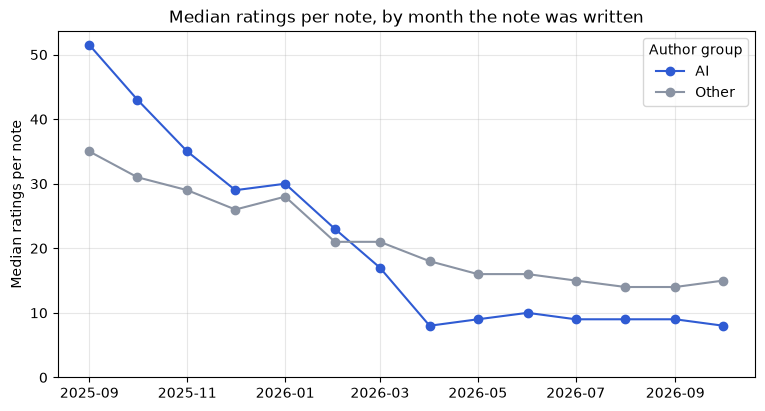

In [7]:
by_month = frames[2]
fig, ax = plt.subplots(figsize=(9, 4.5))
for group, df in by_month.groupby("author_group"):
    ax.plot(df["month"], df["median_ratings"], marker="o", label=group, color=COLORS[group])
ax.set_title("Median ratings per note, by month the note was written")
ax.set_ylabel("Median ratings per note")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(title="Author group")
plt.show()

**Reading:** until Feb 2026 AI notes got as many or more ratings than other notes, from Apr 2026 clearly fewer. The change coincides with the jump in AI volume, but this data does not show why.

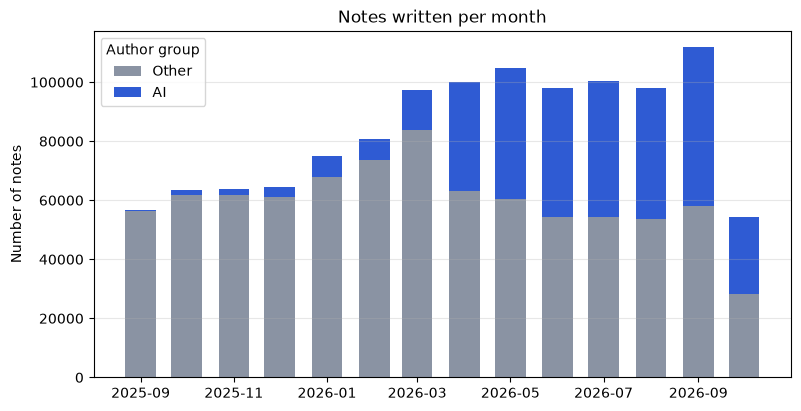

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pivot = monthly.pivot(index="month", columns="author_group", values="notes").fillna(0)
ax.bar(pivot.index, pivot["Other"], width=20, label="Other", color=COLORS["Other"])
ax.bar(pivot.index, pivot["AI"], width=20, bottom=pivot["Other"], label="AI", color=COLORS["AI"])
ax.set_title("Notes written per month")
ax.set_ylabel("Number of notes")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Author group")
plt.show()

## 5. How fast does the first rating arrive?
Hours from note creation to its first rating (notes with at least one rating).

In [9]:
display(run_sql_file("06_time_to_first_rating.sql")[0])

,author_group,notes,median_hours,p90_hours
0,AI,331203,0.17,2.56
1,Other,837336,0.15,2.43


## 6. Summary and limits
- AI notes reach Helpful more often than other notes in every month since Sep 2025, and the gap narrowed after spring 2026.
- Time to a first non-"Needs More Ratings" status is about the same for both groups, and so is the time to the first rating (about 10 minutes).
- Since Apr 2026 AI notes get fewer ratings per note than other notes written in the same month.
- All results are descriptive. Tweet selection, topics and author differences are not controlled, the AI group is defined by current account state, and the latest months are still maturing. See the README for the full list of limitations.